<a href="https://colab.research.google.com/github/JeevasriNagarajan24696/Solar-Panel-Defect-Classification/blob/main/Solar_Panel_Defect_Classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
!pip -q install kagglehub

import kagglehub

dataset_path = kagglehub.dataset_download(
    "pythonafroz/solar-panel-images"
)

print("Dataset downloaded to:", dataset_path)

Using Colab cache for faster access to the 'solar-panel-images' dataset.
Dataset downloaded to: /kaggle/input/solar-panel-images


In [4]:
import os

print("Dataset location:", dataset_path)

for folder, subfolders, files in os.walk(dataset_path):
    print("Folder:", folder)
    print("Number of files:", len(files))
    print("-------------------------")

Dataset location: /kaggle/input/solar-panel-images
Folder: /kaggle/input/solar-panel-images
Number of files: 0
-------------------------
Folder: /kaggle/input/solar-panel-images/Faulty_solar_panel
Number of files: 0
-------------------------
Folder: /kaggle/input/solar-panel-images/Faulty_solar_panel/Snow-Covered
Number of files: 124
-------------------------
Folder: /kaggle/input/solar-panel-images/Faulty_solar_panel/Dusty
Number of files: 191
-------------------------
Folder: /kaggle/input/solar-panel-images/Faulty_solar_panel/Electrical-damage
Number of files: 104
-------------------------
Folder: /kaggle/input/solar-panel-images/Faulty_solar_panel/Clean
Number of files: 194
-------------------------
Folder: /kaggle/input/solar-panel-images/Faulty_solar_panel/Bird-drop
Number of files: 192
-------------------------
Folder: /kaggle/input/solar-panel-images/Faulty_solar_panel/Bird-drop/New
Number of files: 16
-------------------------
Folder: /kaggle/input/solar-panel-images/Faulty_so

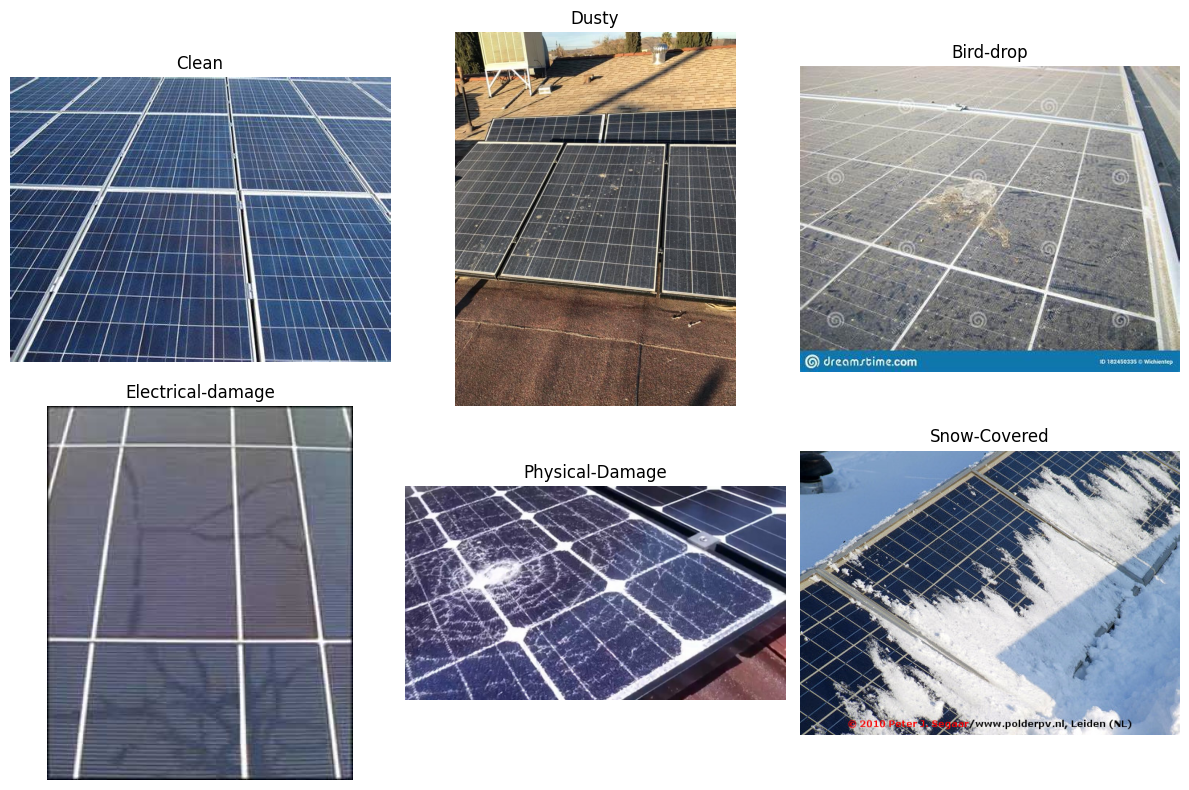

In [5]:

import os
import matplotlib.pyplot as plt
from PIL import Image

data_dir = os.path.join(dataset_path, "Faulty_solar_panel")

classes = [
    "Clean",
    "Dusty",
    "Bird-drop",
    "Electrical-damage",
    "Physical-Damage",
    "Snow-Covered"
]

fig, axes = plt.subplots(2, 3, figsize=(12, 8))

for ax, class_name in zip(axes.flat, classes):
    folder = os.path.join(data_dir, class_name)

    image_files = []

    for root, dirs, files in os.walk(folder):
        for file in files:
            if file.lower().endswith((".jpg", ".jpeg", ".png", ".webp")):
                image_files.append(os.path.join(root, file))

    if image_files:
        with Image.open(image_files[0]) as img:
            ax.imshow(img.convert("RGB"))

    ax.set_title(class_name)
    ax.axis("off")

plt.tight_layout()
plt.show()

In [6]:

from PIL import Image
from collections import Counter
import os

image_sizes = Counter()
valid_images = 0
invalid_images = []

for root, dirs, files in os.walk(data_dir):
    for file in files:
        file_path = os.path.join(root, file)

        if file.lower().endswith((".jpg", ".jpeg", ".png", ".webp")):
            try:
                with Image.open(file_path) as img:
                    img.verify()

                with Image.open(file_path) as img:
                    image_sizes[img.size] += 1

                valid_images += 1

            except Exception:
                invalid_images.append(file_path)

print("Valid images:", valid_images)
print("Invalid images:", len(invalid_images))
print("\nMost common image dimensions:")

for size, count in image_sizes.most_common(10):
    print(size, ":", count, "images")

Valid images: 885
Invalid images: 0

Most common image dimensions:
(720, 960) : 58 images
(2048, 1152) : 23 images
(2048, 1536) : 22 images
(474, 355) : 22 images
(1536, 2048) : 22 images
(800, 600) : 18 images
(960, 720) : 18 images
(474, 632) : 15 images
(1024, 768) : 12 images
(800, 533) : 10 images


In [7]:

from collections import Counter
import os

class_counts = Counter()

for class_name in classes:
    folder = os.path.join(data_dir, class_name)

    for root, dirs, files in os.walk(folder):
        for file in files:
            if file.lower().endswith(
                (".jpg", ".jpeg", ".png", ".webp")
            ):
                class_counts[class_name] += 1

for class_name, count in class_counts.items():
    print(f"{class_name}: {count}")

print("Total images:", sum(class_counts.values()))

Clean: 193
Dusty: 190
Bird-drop: 207
Electrical-damage: 103
Physical-Damage: 69
Snow-Covered: 123
Total images: 885


In [8]:

import os
import hashlib
from collections import defaultdict

hashes = defaultdict(list)

for class_name in classes:
    folder = os.path.join(data_dir, class_name)

    for root, dirs, files in os.walk(folder):
        for file in files:
            if file.lower().endswith(
                (".jpg", ".jpeg", ".png", ".webp")
            ):
                path = os.path.join(root, file)

                with open(path, "rb") as f:
                    file_hash = hashlib.sha256(f.read()).hexdigest()

                hashes[file_hash].append(path)

duplicates = [
    paths for paths in hashes.values()
    if len(paths) > 1
]

print("Total images:", sum(len(v) for v in hashes.values()))
print("Duplicate groups:", len(duplicates))
print("Extra duplicate copies:",
      sum(len(group) - 1 for group in duplicates))

for group in duplicates[:5]:
    print("\nDuplicate group:")
    for path in group:
        print(path)

Total images: 885
Duplicate groups: 74
Extra duplicate copies: 91

Duplicate group:
/kaggle/input/solar-panel-images/Faulty_solar_panel/Clean/Clean (87).jpg
/kaggle/input/solar-panel-images/Faulty_solar_panel/Clean/Clean (90).jpg
/kaggle/input/solar-panel-images/Faulty_solar_panel/Clean/Clean (19).jpg

Duplicate group:
/kaggle/input/solar-panel-images/Faulty_solar_panel/Clean/Clean (173).jpg
/kaggle/input/solar-panel-images/Faulty_solar_panel/Clean/Clean (178).jpg

Duplicate group:
/kaggle/input/solar-panel-images/Faulty_solar_panel/Clean/Clean (188).jpg
/kaggle/input/solar-panel-images/Faulty_solar_panel/Clean/Clean (132).jpg

Duplicate group:
/kaggle/input/solar-panel-images/Faulty_solar_panel/Clean/Clean (183).jpg
/kaggle/input/solar-panel-images/Faulty_solar_panel/Clean/Clean (30).jpg

Duplicate group:
/kaggle/input/solar-panel-images/Faulty_solar_panel/Clean/Clean (153).jpg
/kaggle/input/solar-panel-images/Faulty_solar_panel/Clean/Clean (157).jpg


In [9]:

from collections import Counter

cross_class_duplicates = []

for group in duplicates:
    labels = set()

    for path in group:
        relative_path = os.path.relpath(path, data_dir)
        class_name = relative_path.split(os.sep)[0]
        labels.add(class_name)

    if len(labels) > 1:
        cross_class_duplicates.append(group)

print("Duplicate groups across different classes:",
      len(cross_class_duplicates))

for group in cross_class_duplicates[:10]:
    print("\nConflicting duplicate group:")
    for path in group:
        print(path)


Duplicate groups across different classes: 2

Conflicting duplicate group:
/kaggle/input/solar-panel-images/Faulty_solar_panel/Dusty/Dust (187).jpg
/kaggle/input/solar-panel-images/Faulty_solar_panel/Bird-drop/Bird (193).jpg

Conflicting duplicate group:
/kaggle/input/solar-panel-images/Faulty_solar_panel/Bird-drop/Bird (184).jpg
/kaggle/input/solar-panel-images/Faulty_solar_panel/Bird-drop/Bird (46).jpg
/kaggle/input/solar-panel-images/Faulty_solar_panel/Bird-drop/Bird (57).jpg
/kaggle/input/solar-panel-images/Faulty_solar_panel/Bird-drop/Bird (22).jpg
/kaggle/input/solar-panel-images/Faulty_solar_panel/Bird-drop/Bird (176).jpg
/kaggle/input/solar-panel-images/Faulty_solar_panel/Physical-Damage/Physical (51).jpg


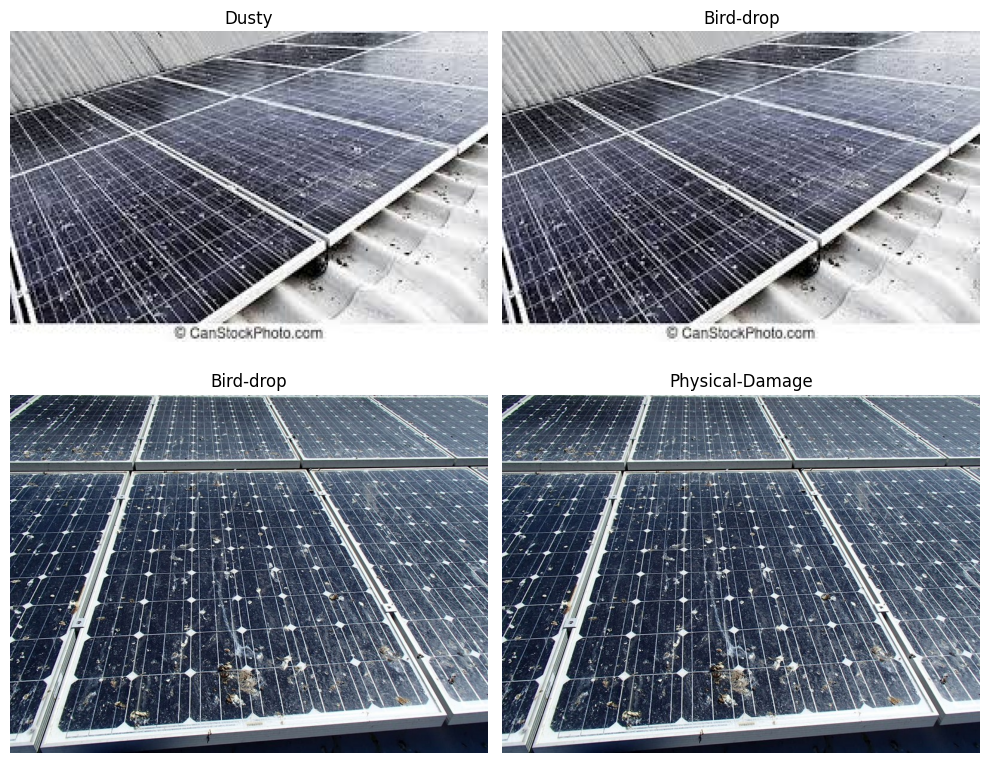

In [10]:

import matplotlib.pyplot as plt
from PIL import Image
import os

fig, axes = plt.subplots(
    len(cross_class_duplicates), 2,
    figsize=(10, 8)
)

for i, group in enumerate(cross_class_duplicates):
    selected = []
    seen_labels = set()

    for path in group:
        label = os.path.relpath(path, data_dir).split(os.sep)[0]

        if label not in seen_labels:
            selected.append((path, label))
            seen_labels.add(label)

    for j, (path, label) in enumerate(selected[:2]):
        with Image.open(path) as img:
            axes[i, j].imshow(img.convert("RGB"))

        axes[i, j].set_title(label)
        axes[i, j].axis("off")

plt.tight_layout()
plt.show()


In [11]:

cleaned_images = []
excluded_hashes = set()

# Identify hashes with conflicting labels
for group in cross_class_duplicates:
    with open(group[0], "rb") as f:
        excluded_hashes.add(
            hashlib.sha256(f.read()).hexdigest()
        )

# Keep one image per unique hash
for file_hash, paths in hashes.items():

    if file_hash in excluded_hashes:
        continue

    image_path = paths[0]

    class_name = os.path.relpath(
        image_path, data_dir
    ).split(os.sep)[0]

    cleaned_images.append((image_path, class_name))

print("Original images:", 885)
print("Unique images before conflict removal:", len(hashes))
print("Conflicting groups removed:", len(excluded_hashes))
print("Cleaned dataset images:", len(cleaned_images))


Original images: 885
Unique images before conflict removal: 794
Conflicting groups removed: 2
Cleaned dataset images: 792


In [12]:

from sklearn.model_selection import train_test_split

# Separate image paths and class labels
image_paths = [item[0] for item in cleaned_images]
labels = [item[1] for item in cleaned_images]

# First split: 70% training, 30% remaining
train_paths, temp_paths, train_labels, temp_labels = train_test_split(
    image_paths,
    labels,
    test_size=0.30,
    random_state=42,
    stratify=labels
)

# Second split: remaining 30% into validation and test
val_paths, test_paths, val_labels, test_labels = train_test_split(
    temp_paths,
    temp_labels,
    test_size=0.50,
    random_state=42,
    stratify=temp_labels
)

print("Training images:", len(train_paths))
print("Validation images:", len(val_paths))
print("Testing images:", len(test_paths))

print("Total:", len(train_paths) + len(val_paths) + len(test_paths))


Training images: 554
Validation images: 119
Testing images: 119
Total: 792


In [13]:

import pandas as pd
from collections import Counter

train_counts = Counter(train_labels)
val_counts = Counter(val_labels)
test_counts = Counter(test_labels)

distribution = pd.DataFrame({
    "Training": [train_counts[c] for c in classes],
    "Validation": [val_counts[c] for c in classes],
    "Testing": [test_counts[c] for c in classes]
}, index=classes)

distribution["Total"] = distribution.sum(axis=1)

print(distribution)
print("\nTotal per split:")
print(distribution.sum(axis=0))


                   Training  Validation  Testing  Total
Clean                   130          28       28    186
Dusty                   127          28       27    182
Bird-drop               110          23       24    157
Electrical-damage        64          13       14     91
Physical-Damage          44          10        9     63
Snow-Covered             79          17       17    113

Total per split:
Training      554
Validation    119
Testing       119
Total         792
dtype: int64


In [14]:

import tensorflow as tf

IMG_SIZE = (224, 224)

def preprocess_image(image_path, label):

    # Read the image
    image = tf.io.read_file(image_path)

    # Decode image into 3 RGB channels
    image = tf.io.decode_image(
        image,
        channels=3,
        expand_animations=False
    )

    # Resize while maintaining aspect ratio
    image = tf.image.resize_with_pad(
        image,
        IMG_SIZE[0],
        IMG_SIZE[1]
    )

    # Normalize pixel values to 0–1
    image = tf.cast(image, tf.float32) / 255.0

    return image, label

print("Image preprocessing function created successfully!")


Image preprocessing function created successfully!


In [28]:

BATCH_SIZE = 32

# Convert class names into numerical labels
class_to_index = {
    class_name: i
    for i, class_name in enumerate(classes)
}

def create_dataset(paths, labels, training=False):

    numeric_labels = [
        class_to_index[label] for label in labels
    ]

    dataset = tf.data.Dataset.from_tensor_slices(
        (paths, numeric_labels)
    )

    # Shuffle training data only
    if training:
        dataset = dataset.shuffle(
            buffer_size=len(paths),
            seed=42
        )

    # Apply preprocessing
    dataset = dataset.map(
        preprocess_image,
        num_parallel_calls=tf.data.AUTOTUNE
    )

    # Group images into batches
    dataset = dataset.batch(BATCH_SIZE)

    # Improve data loading performance
    dataset = dataset.prefetch(tf.data.AUTOTUNE)

    return dataset

train_ds = create_dataset(
    train_paths, train_labels, training=True
)

val_ds = create_dataset(
    val_paths, val_labels
)

test_ds = create_dataset(
    test_paths, test_labels
)

print("Training dataset created!")
print("Validation dataset created!")
print("Testing dataset created!")
print("Number of classes:", len(classes))


Training dataset created!
Validation dataset created!
Testing dataset created!
Number of classes: 6


In [16]:

# Take one batch from the training dataset
for images, labels in train_ds.take(1):

    print("Image batch shape:", images.shape)
    print("Label batch shape:", labels.shape)

    print("Minimum pixel value:",
          tf.reduce_min(images).numpy())

    print("Maximum pixel value:",
          tf.reduce_max(images).numpy())

    print("Sample labels:", labels.numpy())


Image batch shape: (32, 224, 224, 3)
Label batch shape: (32,)
Minimum pixel value: 0.0
Maximum pixel value: 1.0
Sample labels: [5 0 4 5 4 2 2 2 0 5 1 2 3 5 3 1 1 1 0 2 1 1 2 1 1 0 0 0 1 0 0 1]


In [17]:

from tensorflow import keras
from tensorflow.keras import layers

tf.keras.utils.set_random_seed(42)

baseline_model = keras.Sequential([
    layers.Input(shape=(224, 224, 3)),

    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(128, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.GlobalAveragePooling2D(),

    layers.Dense(64, activation="relu"),

    layers.Dense(6, activation="softmax")
])

baseline_model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 6)              │           390 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,894 (398.02 KB)

 Trainable params: 101,894 (398.02 KB)

 Non-trainable params: 0 (0.00 B)

In [18]:

baseline_model.compile(
    optimizer=keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Baseline CNN compiled successfully!")


Baseline CNN compiled successfully!


In [19]:

# Train the baseline CNN

EPOCHS = 15

baseline_history = baseline_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS
)

print("Baseline CNN training completed!")


Epoch 1/15
18/18 ━━━━━━━━━━━━━━━━━━━━ 45s 2s/step - accuracy: 0.2653 - loss: 1.7432 - val_accuracy: 0.2353 - val_loss: 1.7565
Epoch 2/15
18/18 ━━━━━━━━━━━━━━━━━━━━ 41s 2s/step - accuracy: 0.3051 - loss: 1.6838 - val_accuracy: 0.3445 - val_loss: 1.6519
Epoch 3/15
18/18 ━━━━━━━━━━━━━━━━━━━━ 82s 2s/step - accuracy: 0.3664 - loss: 1.6027 - val_accuracy: 0.3782 - val_loss: 1.5657
Epoch 4/15
18/18 ━━━━━━━━━━━━━━━━━━━━ 85s 2s/step - accuracy: 0.3845 - loss: 1.5325 - val_accuracy: 0.4370 - val_loss: 1.5064
Epoch 5/15
18/18 ━━━━━━━━━━━━━━━━━━━━ 82s 2s/step - accuracy: 0.3935 - loss: 1.4984 - val_accuracy: 0.4958 - val_loss: 1.4747
Epoch 6/15
18/18 ━━━━━━━━━━━━━━━━━━━━ 44s 2s/step - accuracy: 0.4043 - loss: 1.4629 - val_accuracy: 0.4118 - val_loss: 1.4693
Epoch 7/15
18/18 ━━━━━━━━━━━━━━━━━━━━ 45s 2s/step - accuracy: 0.3953 - loss: 1.4801 - val_accuracy: 0.3697 - val_loss: 1.5153
Epoch 8/15
18/18 ━━━━━━━━━━━━━━━━━━━━ 79s 2s/step - accuracy: 0.3881 - loss: 1.4746 - val_accuracy: 0.4202 - val_loss:

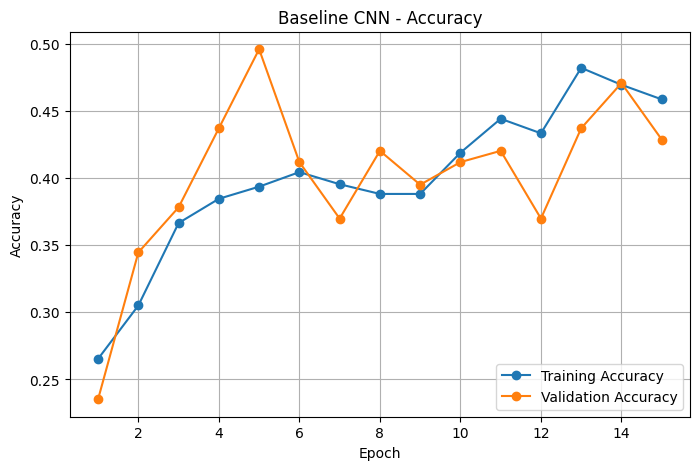

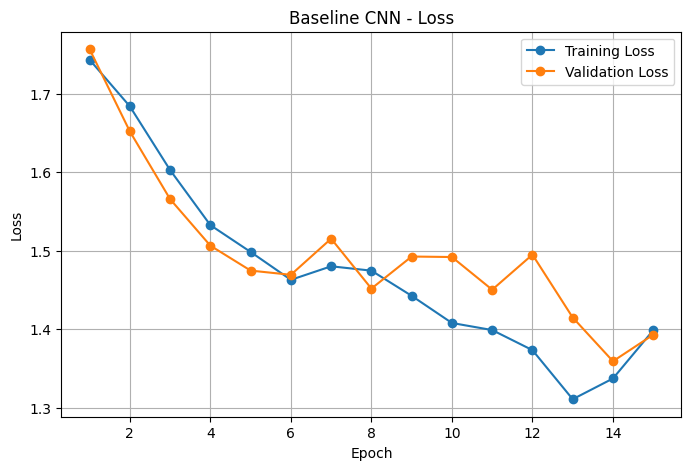

In [20]:

import matplotlib.pyplot as plt

history = baseline_history.history

epochs = range(1, len(history["accuracy"]) + 1)

# Plot accuracy
plt.figure(figsize=(8, 5))

plt.plot(
    epochs,
    history["accuracy"],
    label="Training Accuracy",
    marker="o"
)

plt.plot(
    epochs,
    history["val_accuracy"],
    label="Validation Accuracy",
    marker="o"
)

plt.title("Baseline CNN - Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()

# Plot loss
plt.figure(figsize=(8, 5))

plt.plot(
    epochs,
    history["loss"],
    label="Training Loss",
    marker="o"
)

plt.plot(
    epochs,
    history["val_loss"],
    label="Validation Loss",
    marker="o"
)

plt.title("Baseline CNN - Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()


In [21]:

import os
import json

# Create a folder for our results
os.makedirs("/content/solar_panel_results", exist_ok=True)

# Save the trained baseline model
baseline_model.save(
    "/content/solar_panel_results/baseline_cnn.keras"
)

# Save training history
with open(
    "/content/solar_panel_results/baseline_history.json",
    "w"
) as f:
    json.dump(baseline_history.history, f)

print("Baseline CNN model saved successfully!")
print("Training history saved successfully!")


Baseline CNN model saved successfully!
Training history saved successfully!


In [22]:

from google.colab import files

# Download trained baseline CNN model
files.download(
    "/content/solar_panel_results/baseline_cnn.keras"
)

# Download training history
files.download(
    "/content/solar_panel_results/baseline_history.json"
)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [23]:
import tensorflow as tf
from tensorflow.keras import layers

# Step 9.2 - Create data augmentation layers
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.05),
    layers.RandomZoom(0.1)
], name="data_augmentation")

print("Data augmentation layers created successfully!")

Data augmentation layers created successfully!


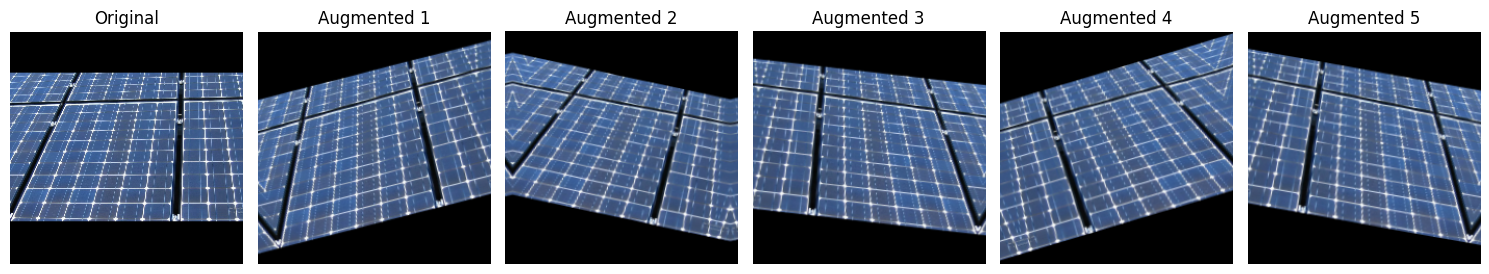

In [24]:

import matplotlib.pyplot as plt

# Take one batch from our training dataset
for images, labels in train_ds.take(1):
    sample_image = images[0]
    break

# Display the original image and 5 augmented versions
plt.figure(figsize=(15, 3))

plt.subplot(1, 6, 1)
plt.imshow(sample_image.numpy())
plt.title("Original")
plt.axis("off")

for i in range(5):
    augmented_image = data_augmentation(
        tf.expand_dims(sample_image, axis=0),
        training=True
    )

    plt.subplot(1, 6, i + 2)
    plt.imshow(
        tf.clip_by_value(augmented_image[0], 0, 1).numpy()
    )
    plt.title(f"Augmented {i+1}")
    plt.axis("off")

plt.tight_layout()
plt.show()


In [25]:
import tensorflow as tf
from tensorflow.keras import layers, models

# Create a new CNN with data augmentation
augmented_model = models.Sequential([
    layers.Input(shape=(224, 224, 3)),

    # Apply augmentation during training
    data_augmentation,

    # Same CNN architecture as baseline
    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(128, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.GlobalAveragePooling2D(),

    layers.Dense(64, activation="relu"),
    layers.Dense(6, activation="softmax")
])

# Display the architecture
augmented_model.summary()

print("Augmented CNN model created successfully!")

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ data_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 6)              │           390 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,894 (398.02 KB)

 Trainable params: 101,894 (398.02 KB)

 Non-trainable params: 0 (0.00 B)

Augmented CNN model created successfully!


In [26]:
# Step 9.5 - Compile the augmented CNN

augmented_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Augmented CNN compiled successfully!")

Augmented CNN compiled successfully!


In [27]:
# Step 9.6 - Train the augmented CNN

augmented_history = augmented_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15
)

print("Augmented CNN training completed!")

Epoch 1/15
18/18 ━━━━━━━━━━━━━━━━━━━━ 51s 3s/step - accuracy: 0.2310 - loss: 1.7384 - val_accuracy: 0.2353 - val_loss: 1.7301
Epoch 2/15
18/18 ━━━━━━━━━━━━━━━━━━━━ 49s 3s/step - accuracy: 0.2924 - loss: 1.7145 - val_accuracy: 0.2689 - val_loss: 1.6871
Epoch 3/15
18/18 ━━━━━━━━━━━━━━━━━━━━ 80s 3s/step - accuracy: 0.3628 - loss: 1.6410 - val_accuracy: 0.3950 - val_loss: 1.5913
Epoch 4/15
18/18 ━━━━━━━━━━━━━━━━━━━━ 48s 3s/step - accuracy: 0.3628 - loss: 1.5916 - val_accuracy: 0.4202 - val_loss: 1.5025
Epoch 5/15
18/18 ━━━━━━━━━━━━━━━━━━━━ 81s 3s/step - accuracy: 0.3736 - loss: 1.5403 - val_accuracy: 0.2773 - val_loss: 1.7972
Epoch 6/15
18/18 ━━━━━━━━━━━━━━━━━━━━ 47s 3s/step - accuracy: 0.3574 - loss: 1.5495 - val_accuracy: 0.4538 - val_loss: 1.4525
Epoch 7/15
18/18 ━━━━━━━━━━━━━━━━━━━━ 47s 3s/step - accuracy: 0.4152 - loss: 1.4958 - val_accuracy: 0.3445 - val_loss: 1.7160
Epoch 8/15
18/18 ━━━━━━━━━━━━━━━━━━━━ 52s 3s/step - accuracy: 0.3917 - loss: 1.4713 - val_accuracy: 0.3193 - val_loss:

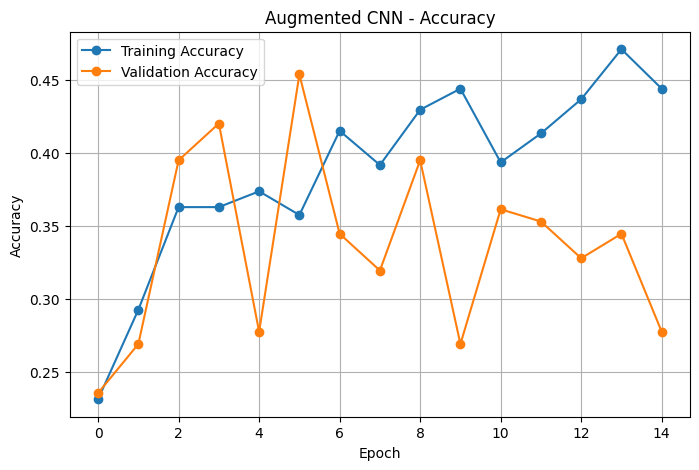

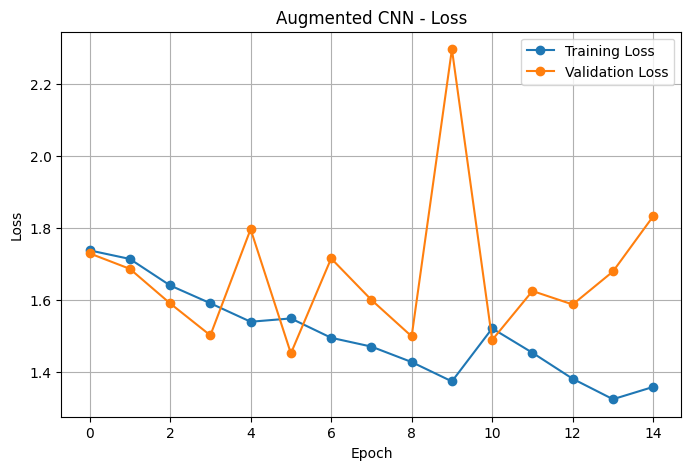

In [29]:

import matplotlib.pyplot as plt

# Step 9.7 - Plot augmented CNN results

# Accuracy graph
plt.figure(figsize=(8, 5))

plt.plot(
    augmented_history.history["accuracy"],
    label="Training Accuracy",
    marker="o"
)

plt.plot(
    augmented_history.history["val_accuracy"],
    label="Validation Accuracy",
    marker="o"
)

plt.title("Augmented CNN - Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()

# Loss graph
plt.figure(figsize=(8, 5))

plt.plot(
    augmented_history.history["loss"],
    label="Training Loss",
    marker="o"
)

plt.plot(
    augmented_history.history["val_loss"],
    label="Validation Loss",
    marker="o"
)

plt.title("Augmented CNN - Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()


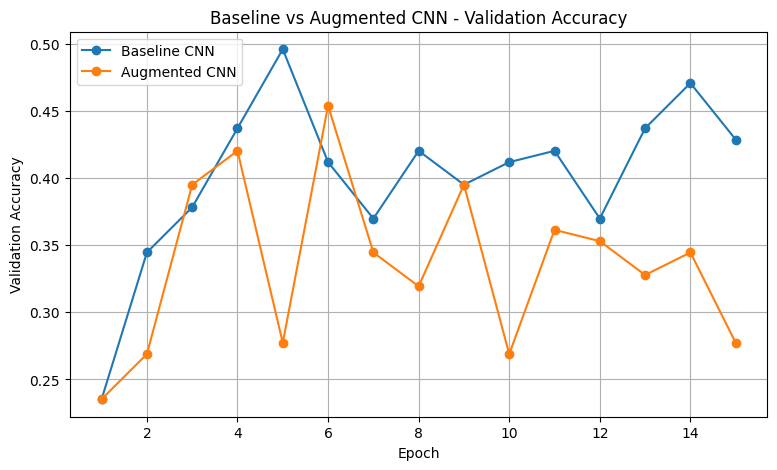

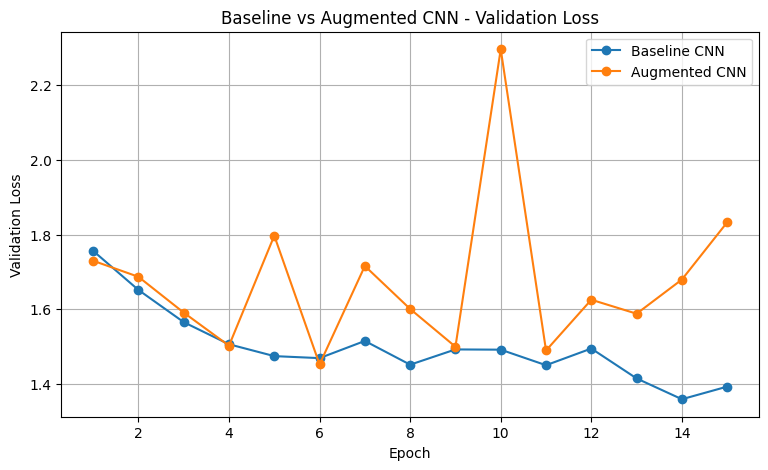

In [30]:

import matplotlib.pyplot as plt

# Step 9.8 - Compare baseline and augmented CNN

epochs = range(1, 16)

plt.figure(figsize=(9, 5))

plt.plot(
    epochs,
    baseline_history.history["val_accuracy"],
    label="Baseline CNN",
    marker="o"
)

plt.plot(
    epochs,
    augmented_history.history["val_accuracy"],
    label="Augmented CNN",
    marker="o"
)

plt.title("Baseline vs Augmented CNN - Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Validation Accuracy")
plt.legend()
plt.grid(True)
plt.show()

# Compare validation loss
plt.figure(figsize=(9, 5))

plt.plot(
    epochs,
    baseline_history.history["val_loss"],
    label="Baseline CNN",
    marker="o"
)

plt.plot(
    epochs,
    augmented_history.history["val_loss"],
    label="Augmented CNN",
    marker="o"
)

plt.title("Baseline vs Augmented CNN - Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Validation Loss")
plt.legend()
plt.grid(True)
plt.show()


In [31]:

import os
import json

# Create results folder if it doesn't exist
os.makedirs("/content/solar_panel_results", exist_ok=True)

# Save augmented CNN model
augmented_model.save(
    "/content/solar_panel_results/augmented_cnn.keras"
)

# Save augmented CNN training history
with open(
    "/content/solar_panel_results/augmented_history.json",
    "w"
) as f:
    json.dump(augmented_history.history, f)

print("Augmented CNN model saved successfully!")
print("Augmented CNN training history saved successfully!")


Augmented CNN model saved successfully!
Augmented CNN training history saved successfully!


In [32]:

from google.colab import files

# Download the trained Augmented CNN model
files.download(
    "/content/solar_panel_results/augmented_cnn.keras"
)

# Download the training history
files.download(
    "/content/solar_panel_results/augmented_history.json"
)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [33]:

import tensorflow as tf
from tensorflow.keras import layers, models

# Step 10.2 - Create Optimized CNN

optimized_model = models.Sequential([

    layers.Input(shape=(224, 224, 3)),

    # Data augmentation
    data_augmentation,

    # First convolution block
    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    # Second convolution block
    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    # Third convolution block
    layers.Conv2D(128, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    # Convert feature maps into feature vector
    layers.GlobalAveragePooling2D(),

    # Fully connected layer
    layers.Dense(64, activation="relu"),

    # Dropout to reduce overfitting
    layers.Dropout(0.3),

    # Output layer for six classes
    layers.Dense(6, activation="softmax")
])

# Display model architecture
optimized_model.summary()

print("Optimized CNN model created successfully!")


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ data_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_8 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_2      │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 6)              │           390 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,894 (398.02 KB)

 Trainable params: 101,894 (398.02 KB)

 Non-trainable params: 0 (0.00 B)

Optimized CNN model created successfully!


In [34]:
import tensorflow as tf
from tensorflow.keras import layers

# Recreate data augmentation layers
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1)
])

print("Data augmentation layers recreated successfully!")

Data augmentation layers recreated successfully!


In [35]:
import tensorflow as tf
from tensorflow.keras import layers, models

# Step 10.2 - Create Optimized CNN

optimized_model = models.Sequential([

    layers.Input(shape=(224, 224, 3)),

    # Data augmentation
    data_augmentation,

    # First convolution block
    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    # Second convolution block
    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    # Third convolution block
    layers.Conv2D(128, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    # Convert feature maps into feature vector
    layers.GlobalAveragePooling2D(),

    # Fully connected layer
    layers.Dense(64, activation="relu"),

    # Dropout to reduce overfitting
    layers.Dropout(0.3),

    # Output layer for six classes
    layers.Dense(6, activation="softmax")
])

# Display model architecture
optimized_model.summary()

print("Optimized CNN model created successfully!")

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential_3 (Sequential)       │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_9 (MaxPooling2D)  │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_10 (Conv2D)              │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_10 (MaxPooling2D) │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_11 (Conv2D)              │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_11 (MaxPooling2D) │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_3      │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 6)              │           390 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,894 (398.02 KB)

 Trainable params: 101,894 (398.02 KB)

 Non-trainable params: 0 (0.00 B)

Optimized CNN model created successfully!


In [36]:
# Step 10.3 - Compile Optimized CNN

optimized_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.0001
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Optimized CNN compiled successfully!")

Optimized CNN compiled successfully!


In [37]:
# Step 10.4 - Train Optimized CNN

from tensorflow.keras.callbacks import EarlyStopping

# Configure early stopping
early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

# Train the optimized CNN
optimized_history = optimized_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=25,
    callbacks=[early_stopping]
)

print("Optimized CNN training completed successfully!")

Epoch 1/25
18/18 ━━━━━━━━━━━━━━━━━━━━ 57s 3s/step - accuracy: 0.1949 - loss: 1.7867 - val_accuracy: 0.2437 - val_loss: 1.7762
Epoch 2/25
18/18 ━━━━━━━━━━━━━━━━━━━━ 83s 3s/step - accuracy: 0.2726 - loss: 1.7698 - val_accuracy: 0.2521 - val_loss: 1.7590
Epoch 3/25
18/18 ━━━━━━━━━━━━━━━━━━━━ 51s 3s/step - accuracy: 0.2978 - loss: 1.7557 - val_accuracy: 0.2689 - val_loss: 1.7350
Epoch 4/25
18/18 ━━━━━━━━━━━━━━━━━━━━ 51s 3s/step - accuracy: 0.2798 - loss: 1.7305 - val_accuracy: 0.2521 - val_loss: 1.7149
Epoch 5/25
18/18 ━━━━━━━━━━━━━━━━━━━━ 52s 3s/step - accuracy: 0.2635 - loss: 1.7166 - val_accuracy: 0.3613 - val_loss: 1.6905
Epoch 6/25
18/18 ━━━━━━━━━━━━━━━━━━━━ 79s 3s/step - accuracy: 0.3014 - loss: 1.6970 - val_accuracy: 0.3193 - val_loss: 1.6792
Epoch 7/25
18/18 ━━━━━━━━━━━━━━━━━━━━ 83s 3s/step - accuracy: 0.3484 - loss: 1.6749 - val_accuracy: 0.3193 - val_loss: 1.6649
Epoch 8/25
18/18 ━━━━━━━━━━━━━━━━━━━━ 49s 3s/step - accuracy: 0.3845 - loss: 1.6563 - val_accuracy: 0.3782 - val_loss:

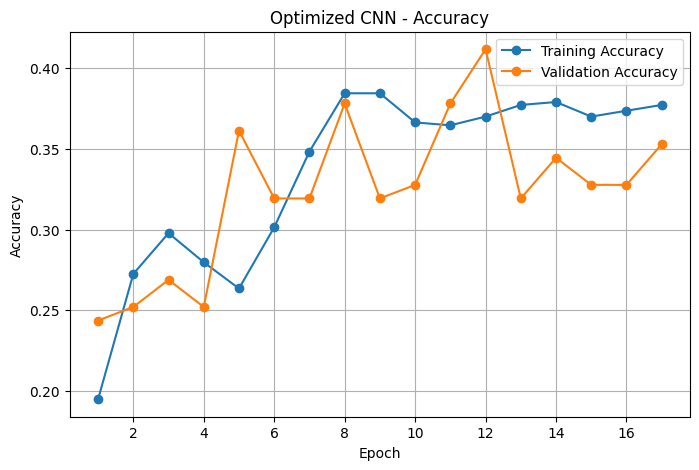

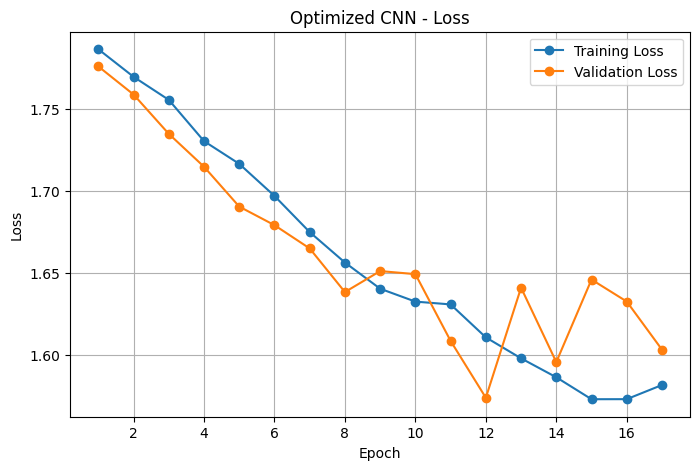

In [38]:
import matplotlib.pyplot as plt

# Step 10.5 - Plot Optimized CNN Results

epochs = range(
    1,
    len(optimized_history.history["accuracy"]) + 1
)

# Accuracy graph
plt.figure(figsize=(8, 5))

plt.plot(
    epochs,
    optimized_history.history["accuracy"],
    label="Training Accuracy",
    marker="o"
)

plt.plot(
    epochs,
    optimized_history.history["val_accuracy"],
    label="Validation Accuracy",
    marker="o"
)

plt.title("Optimized CNN - Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()

# Loss graph
plt.figure(figsize=(8, 5))

plt.plot(
    epochs,
    optimized_history.history["loss"],
    label="Training Loss",
    marker="o"
)

plt.plot(
    epochs,
    optimized_history.history["val_loss"],
    label="Validation Loss",
    marker="o"
)

plt.title("Optimized CNN - Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()

In [39]:
# Step 10.6 - Save Optimized CNN Results

import os
import json

# Create results folder
os.makedirs("/content/solar_panel_results", exist_ok=True)

# Save optimized CNN model
optimized_model.save(
    "/content/solar_panel_results/optimized_cnn.keras"
)

# Save training history
with open(
    "/content/solar_panel_results/optimized_history.json",
    "w"
) as f:
    json.dump(optimized_history.history, f)

print("Optimized CNN model saved successfully!")
print("Optimized CNN training history saved successfully!")

Optimized CNN model saved successfully!
Optimized CNN training history saved successfully!


In [42]:
# Step 10.7 - Download Optimized CNN Results

from google.colab import files

# Download optimized CNN model
files.download(
    "/content/solar_panel_results/optimized_cnn.keras"
)

# Download optimized CNN training history
files.download(
    "/content/solar_panel_results/optimized_history.json"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [43]:
# Step 10.8 - Compare All Three CNN Models

import pandas as pd
import json
import os

# Load saved training histories
results_dir = "/content/solar_panel_results"

history_files = {
    "Baseline CNN": "baseline_history.json",
    "Augmented CNN": "augmented_history.json",
    "Optimized CNN": "optimized_history.json"
}

comparison_results = []

for model_name, filename in history_files.items():
    file_path = os.path.join(results_dir, filename)

    with open(file_path, "r") as f:
        history = json.load(f)

    comparison_results.append({
        "Model": model_name,
        "Best Validation Accuracy (%)":
            max(history["val_accuracy"]) * 100,
        "Lowest Validation Loss":
            min(history["val_loss"]),
        "Epochs Trained":
            len(history["accuracy"])
    })

# Create comparison table
comparison_df = pd.DataFrame(comparison_results)

print("Comparison of Three CNN Models")
print(comparison_df.round(4).to_string(index=False))

Comparison of Three CNN Models
        Model  Best Validation Accuracy (%)  Lowest Validation Loss  Epochs Trained
 Baseline CNN                       49.5798                  1.3592              15
Augmented CNN                       45.3782                  1.4525              15
Optimized CNN                       41.1765                  1.5737              17


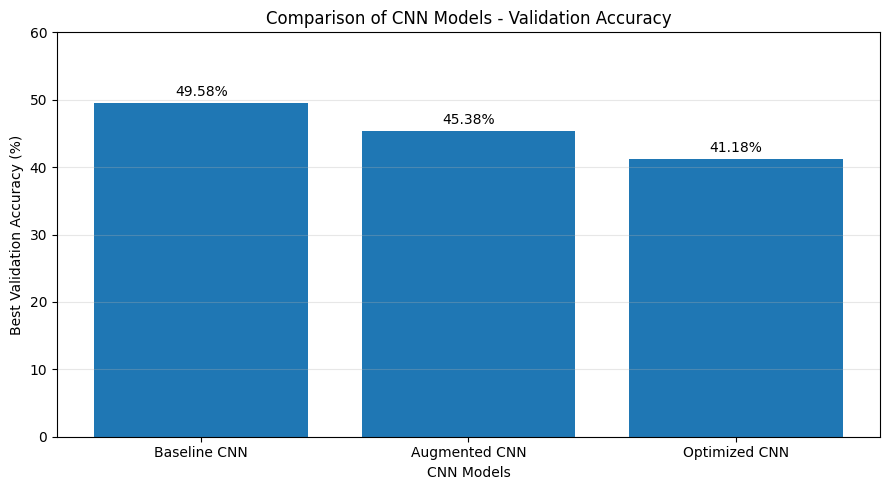

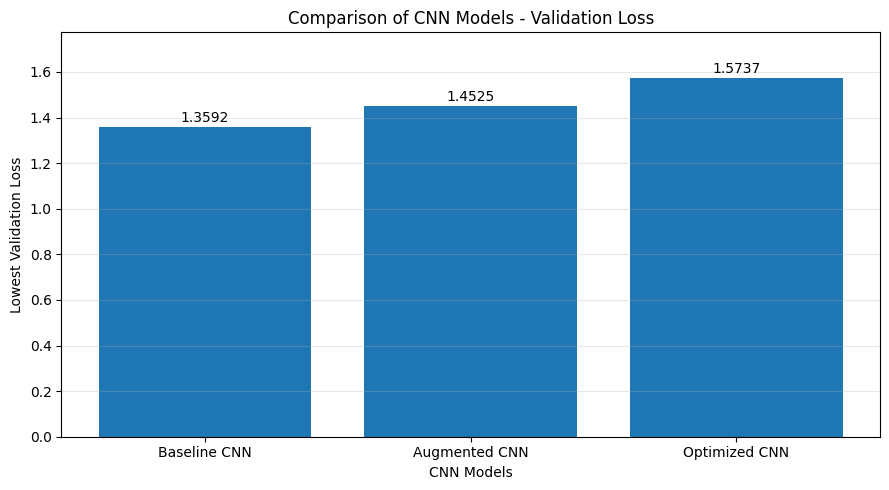

CNN model comparison graphs generated successfully!


In [44]:
# Step 10.9 - Visualize CNN Model Comparison

import matplotlib.pyplot as plt

# Use the comparison table from Step 10.8
models = comparison_df["Model"]
accuracies = comparison_df["Best Validation Accuracy (%)"]
losses = comparison_df["Lowest Validation Loss"]

# Graph 1 - Validation Accuracy
plt.figure(figsize=(9, 5))

bars = plt.bar(models, accuracies)

plt.title("Comparison of CNN Models - Validation Accuracy")
plt.xlabel("CNN Models")
plt.ylabel("Best Validation Accuracy (%)")
plt.ylim(0, 60)

for bar, value in zip(bars, accuracies):
    plt.text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height() + 1,
        f"{value:.2f}%",
        ha="center"
    )

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

# Graph 2 - Validation Loss
plt.figure(figsize=(9, 5))

bars = plt.bar(models, losses)

plt.title("Comparison of CNN Models - Validation Loss")
plt.xlabel("CNN Models")
plt.ylabel("Lowest Validation Loss")

for bar, value in zip(bars, losses):
    plt.text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height() + 0.02,
        f"{value:.4f}",
        ha="center"
    )

plt.ylim(0, max(losses) + 0.2)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

print("CNN model comparison graphs generated successfully!")

In [45]:
# Step 11.1 - Check Test Dataset

if "test_ds" in globals():
    print("Test dataset is available!")

    for images, labels in test_ds.take(1):
        print("Image batch shape:", images.shape)
        print("Label batch shape:", labels.shape)
else:
    print("Test dataset is not available.")
    print("We need to restore it before evaluation.")

Test dataset is available!
Image batch shape: (32, 224, 224, 3)
Label batch shape: (32,)


In [47]:
# Step 11.2 - Evaluate Three CNN Models

import tensorflow as tf
import pandas as pd

# Load saved models if not available in memory
model_paths = {
    "Baseline CNN": "/content/solar_panel_results/baseline_cnn.keras",
    "Augmented CNN": "/content/solar_panel_results/augmented_cnn.keras",
    "Optimized CNN": "/content/solar_panel_results/optimized_cnn.keras"
}

test_results = []

for model_name, model_path in model_paths.items():

    print("\nEvaluating:", model_name)

    model = tf.keras.models.load_model(model_path)

    test_loss, test_accuracy = model.evaluate(
        test_ds,
        verbose=0
    )

    test_results.append({
        "Model": model_name,
        "Test Accuracy (%)": test_accuracy * 100,
        "Test Loss": test_loss
    })

# Create results table
test_comparison_df = pd.DataFrame(test_results)

print("\nTest Dataset Evaluation Results:")
print(test_comparison_df.round(4).to_string(index=False))


Evaluating: Baseline CNN

Evaluating: Augmented CNN

Evaluating: Optimized CNN

Test Dataset Evaluation Results:
        Model  Test Accuracy (%)  Test Loss
 Baseline CNN            42.0168     1.4113
Augmented CNN            34.4538     1.7613
Optimized CNN            35.2941     1.5899


Baseline CNN - Classification Report
                   precision    recall  f1-score   support

            Clean       0.42      0.79      0.55        28
            Dusty       0.39      0.56      0.46        27
        Bird-drop       0.38      0.12      0.19        24
Electrical-damage       0.00      0.00      0.00        14
  Physical-Damage       0.00      0.00      0.00         9
     Snow-Covered       0.50      0.59      0.54        17

         accuracy                           0.42       119
        macro avg       0.28      0.34      0.29       119
     weighted avg       0.34      0.42      0.35       119



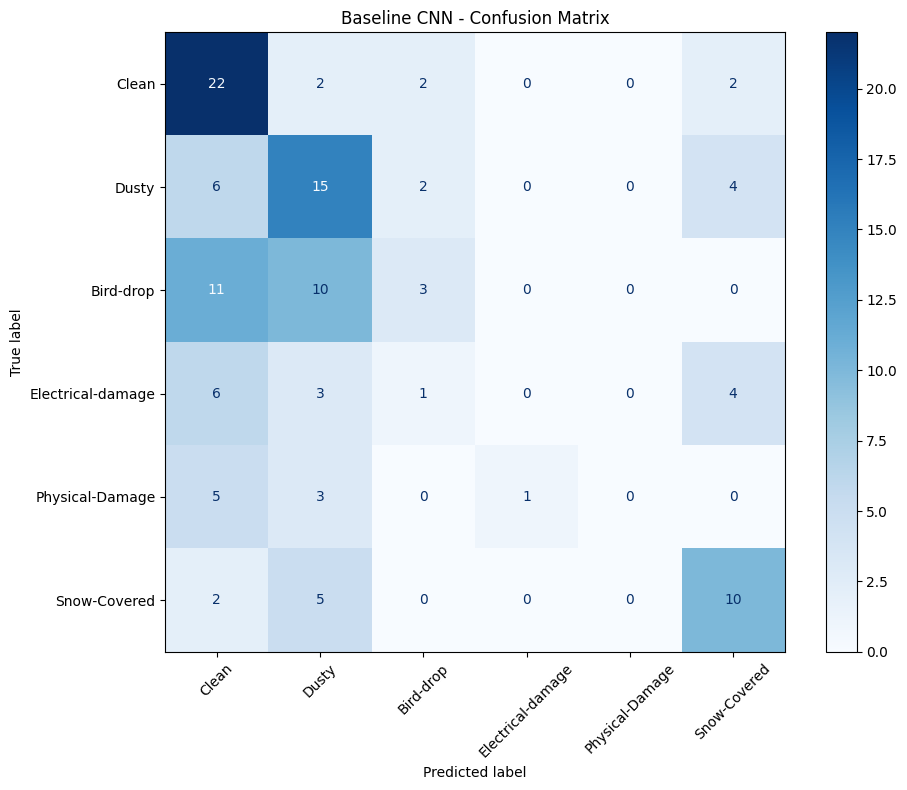

In [48]:
# Step 11.3 - Classification Report and Confusion Matrix

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Load baseline CNN model
baseline_model = tf.keras.models.load_model(
    "/content/solar_panel_results/baseline_cnn.keras"
)

# Collect actual labels and predicted labels
y_true = []
y_pred = []

for images, labels in test_ds:
    predictions = baseline_model.predict(images, verbose=0)

    y_true.extend(labels.numpy())
    y_pred.extend(np.argmax(predictions, axis=1))

y_true = np.array(y_true)
y_pred = np.array(y_pred)

# Class names must match the original label encoding
class_names = [
    "Clean",
    "Dusty",
    "Bird-drop",
    "Electrical-damage",
    "Physical-Damage",
    "Snow-Covered"
]

# Display classification report
print("Baseline CNN - Classification Report")

print(
    classification_report(
        y_true,
        y_pred,
        labels=range(6),
        target_names=class_names,
        zero_division=0
    )
)

# Generate confusion matrix
cm = confusion_matrix(y_true, y_pred, labels=range(6))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

fig, ax = plt.subplots(figsize=(10, 8))
disp.plot(ax=ax, cmap="Blues", xticks_rotation=45)
plt.title("Baseline CNN - Confusion Matrix")
plt.tight_layout()
plt.show()

In [49]:
# Step 11.4 - Save Baseline CNN Evaluation Results

import os
import json
from sklearn.metrics import classification_report

results_dir = "/content/solar_panel_results"
os.makedirs(results_dir, exist_ok=True)

# Save classification report
report = classification_report(
    y_true,
    y_pred,
    labels=range(6),
    target_names=class_names,
    zero_division=0,
    output_dict=True
)

with open(
    os.path.join(results_dir, "baseline_classification_report.json"),
    "w"
) as f:
    json.dump(report, f, indent=4)

# Save confusion matrix
np.savetxt(
    os.path.join(results_dir, "baseline_confusion_matrix.csv"),
    cm,
    delimiter=",",
    fmt="%d"
)

print("Baseline CNN classification report saved!")
print("Baseline CNN confusion matrix saved!")

Baseline CNN classification report saved!
Baseline CNN confusion matrix saved!


In [50]:
# Step 11.5 - Download Baseline CNN Evaluation Results

from google.colab import files

# Download classification report
files.download(
    "/content/solar_panel_results/baseline_classification_report.json"
)

# Download confusion matrix
files.download(
    "/content/solar_panel_results/baseline_confusion_matrix.csv"
)

print("Baseline CNN evaluation files downloaded successfully!")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Baseline CNN evaluation files downloaded successfully!


In [51]:
# Step 12.1 - Import MobileNetV2 Libraries

import tensorflow as tf
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
from tensorflow.keras import layers, models
from tensorflow.keras.callbacks import EarlyStopping

print("TensorFlow version:", tf.__version__)
print("MobileNetV2 libraries imported successfully!")

TensorFlow version: 2.21.0
MobileNetV2 libraries imported successfully!


In [52]:
# Step 12.2 - Load Pretrained MobileNetV2

import tensorflow as tf
from tensorflow.keras.applications import MobileNetV2

# Load pretrained MobileNetV2
base_model = MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False,
    weights="imagenet"
)

# Freeze pretrained layers
base_model.trainable = False

# Display model information
print("MobileNetV2 loaded successfully!")
print("Pretrained layers frozen successfully!")
print("Total layers:", len(base_model.layers))
print("Output shape:", base_model.output_shape)

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
MobileNetV2 loaded successfully!
Pretrained layers frozen successfully!
Total layers: 154
Output shape: (None, 7, 7, 1280)


In [53]:
# Step 12.3 - Build MobileNetV2 Classification Model

import tensorflow as tf
from tensorflow.keras import layers, Model

# Input image shape
inputs = layers.Input(shape=(224, 224, 3))

# Our existing datasets contain pixel values from 0 to 1.
# MobileNetV2 requires pixel values from -1 to 1.
x = layers.Rescaling(scale=2.0, offset=-1.0)(inputs)

# Pretrained MobileNetV2 feature extractor
x = base_model(x, training=False)

# Global Average Pooling
x = layers.GlobalAveragePooling2D()(x)

# Dense layer
x = layers.Dense(128, activation="relu")(x)

# Dropout to reduce overfitting
x = layers.Dropout(0.3)(x)

# Output layer for six solar panel classes
outputs = layers.Dense(6, activation="softmax")(x)

# Create final model
mobilenet_model = Model(
    inputs=inputs,
    outputs=outputs,
    name="Solar_Panel_MobileNetV2"
)

# Display model architecture
mobilenet_model.summary()

print("MobileNetV2 classification model created successfully!")

Model: "Solar_Panel_MobileNetV2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_7 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_4      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 6)              │           774 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,422,726 (9.24 MB)

 Trainable params: 164,742 (643.52 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

MobileNetV2 classification model created successfully!


In [54]:
# Step 12.4 - Compile MobileNetV2 Model

import tensorflow as tf

mobilenet_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.0001
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("MobileNetV2 compiled successfully!")

MobileNetV2 compiled successfully!


In [55]:
# Step 12.5 - Train MobileNetV2 Model

import tensorflow as tf
from tensorflow.keras.callbacks import EarlyStopping

# Early stopping to prevent unnecessary training
early_stopping_mobilenet = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True,
    verbose=1
)

# Train MobileNetV2
mobilenet_history = mobilenet_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=25,
    callbacks=[early_stopping_mobilenet],
    verbose=1
)

print("MobileNetV2 training completed successfully!")

Epoch 1/25
18/18 ━━━━━━━━━━━━━━━━━━━━ 32s 1s/step - accuracy: 0.1877 - loss: 2.1537 - val_accuracy: 0.2773 - val_loss: 1.6943
Epoch 2/25
18/18 ━━━━━━━━━━━━━━━━━━━━ 41s 1s/step - accuracy: 0.2852 - loss: 1.7228 - val_accuracy: 0.4202 - val_loss: 1.4978
Epoch 3/25
18/18 ━━━━━━━━━━━━━━━━━━━━ 24s 1s/step - accuracy: 0.3791 - loss: 1.5377 - val_accuracy: 0.4874 - val_loss: 1.3657
Epoch 4/25
18/18 ━━━━━━━━━━━━━━━━━━━━ 25s 1s/step - accuracy: 0.5000 - loss: 1.3467 - val_accuracy: 0.5042 - val_loss: 1.2539
Epoch 5/25
18/18 ━━━━━━━━━━━━━━━━━━━━ 39s 1s/step - accuracy: 0.5632 - loss: 1.2052 - val_accuracy: 0.5714 - val_loss: 1.1675
Epoch 6/25
18/18 ━━━━━━━━━━━━━━━━━━━━ 25s 1s/step - accuracy: 0.5975 - loss: 1.1287 - val_accuracy: 0.6050 - val_loss: 1.0967
Epoch 7/25
18/18 ━━━━━━━━━━━━━━━━━━━━ 25s 1s/step - accuracy: 0.6047 - loss: 1.0610 - val_accuracy: 0.6471 - val_loss: 1.0357
Epoch 8/25
18/18 ━━━━━━━━━━━━━━━━━━━━ 42s 1s/step - accuracy: 0.6408 - loss: 0.9821 - val_accuracy: 0.6891 - val_loss:

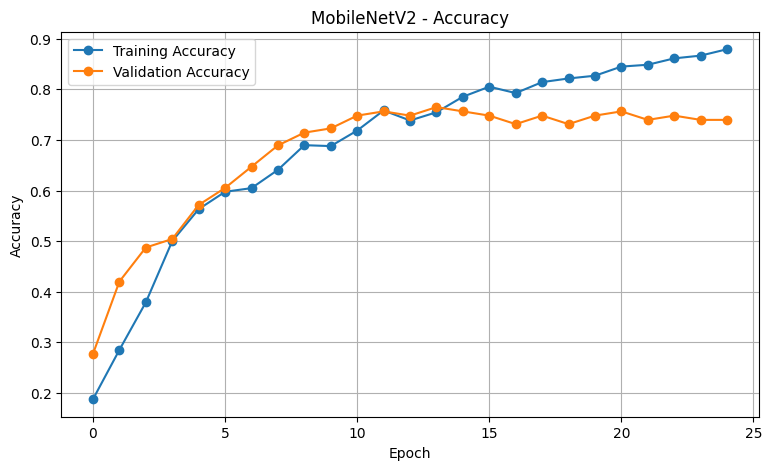

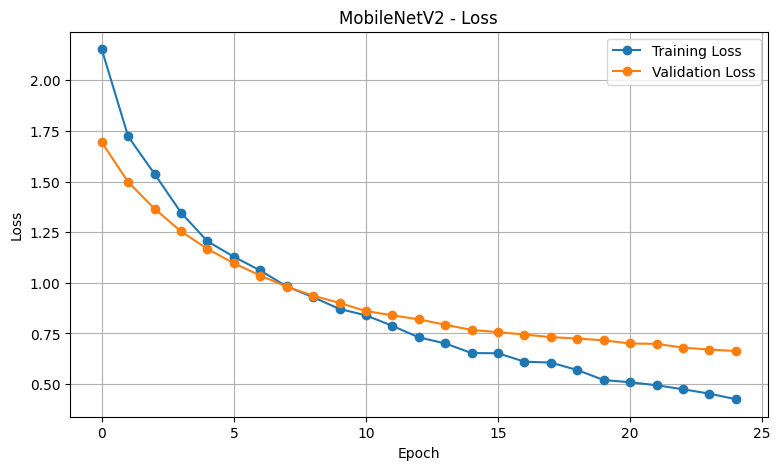

MobileNetV2 training graphs generated successfully!


In [56]:

# Step 12.6 - Plot MobileNetV2 Training Results

import matplotlib.pyplot as plt

# Accuracy graph
plt.figure(figsize=(9, 5))

plt.plot(
    mobilenet_history.history["accuracy"],
    label="Training Accuracy",
    marker="o"
)

plt.plot(
    mobilenet_history.history["val_accuracy"],
    label="Validation Accuracy",
    marker="o"
)

plt.title("MobileNetV2 - Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()

# Loss graph
plt.figure(figsize=(9, 5))

plt.plot(
    mobilenet_history.history["loss"],
    label="Training Loss",
    marker="o"
)

plt.plot(
    mobilenet_history.history["val_loss"],
    label="Validation Loss",
    marker="o"
)

plt.title("MobileNetV2 - Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()

print("MobileNetV2 training graphs generated successfully!")

In [57]:

# Step 12.7 - Save MobileNetV2 Model and History

import os
import json

# Create results folder
os.makedirs(
    "/content/solar_panel_results",
    exist_ok=True
)

# Save trained MobileNetV2 model
mobilenet_model.save(
    "/content/solar_panel_results/mobilenetv2.keras"
)

# Save training history
with open(
    "/content/solar_panel_results/mobilenetv2_history.json",
    "w"
) as f:
    json.dump(mobilenet_history.history, f)

print("MobileNetV2 model saved successfully!")
print("MobileNetV2 training history saved successfully!")


MobileNetV2 model saved successfully!
MobileNetV2 training history saved successfully!


In [58]:

# Step 12.8 - Download MobileNetV2 Results

from google.colab import files

# Download trained MobileNetV2 model
files.download(
    "/content/solar_panel_results/mobilenetv2.keras"
)

# Download MobileNetV2 training history
files.download(
    "/content/solar_panel_results/mobilenetv2_history.json"
)

print("MobileNetV2 results downloaded successfully!")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

MobileNetV2 results downloaded successfully!


In [59]:

# Step 12.9 - Evaluate MobileNetV2 on Test Dataset

import tensorflow as tf

# Load saved MobileNetV2 model
mobilenet_model = tf.keras.models.load_model(
    "/content/solar_panel_results/mobilenetv2.keras"
)

# Evaluate on unseen test images
mobilenet_test_loss, mobilenet_test_accuracy = (
    mobilenet_model.evaluate(
        test_ds,
        verbose=1
    )
)

# Display results
print("\nMobileNetV2 Test Results")
print(
    f"Test Accuracy: {mobilenet_test_accuracy * 100:.2f}%"
)
print(
    f"Test Loss: {mobilenet_test_loss:.4f}"
)

print("MobileNetV2 test evaluation completed successfully!")


4/4 ━━━━━━━━━━━━━━━━━━━━ 8s 1s/step - accuracy: 0.6723 - loss: 0.9064

MobileNetV2 Test Results
Test Accuracy: 67.23%
Test Loss: 0.9064
MobileNetV2 test evaluation completed successfully!


MobileNetV2 - Classification Report
                   precision    recall  f1-score   support

            Clean       0.63      0.86      0.73        28
            Dusty       0.69      0.41      0.51        27
        Bird-drop       0.60      0.62      0.61        24
Electrical-damage       0.68      0.93      0.79        14
  Physical-Damage       0.57      0.44      0.50         9
     Snow-Covered       0.93      0.76      0.84        17

         accuracy                           0.67       119
        macro avg       0.68      0.67      0.66       119
     weighted avg       0.68      0.67      0.66       119



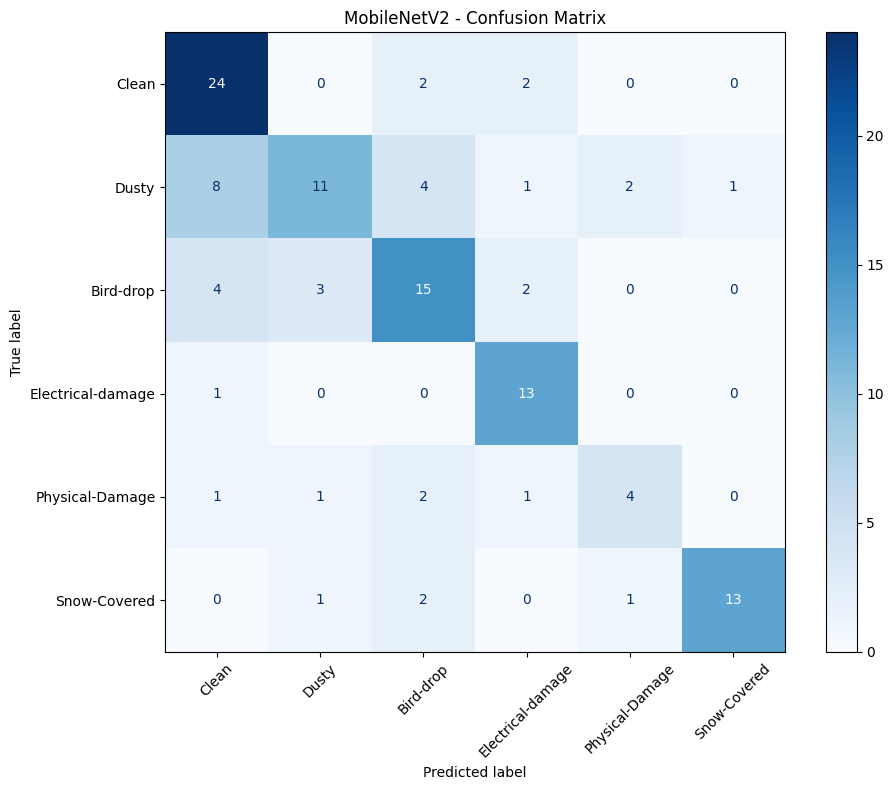

MobileNetV2 classification evaluation completed!


In [60]:

# Step 12.10 - MobileNetV2 Classification Report
# and Confusion Matrix

import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Class names in original label order
class_names = [
    "Clean",
    "Dusty",
    "Bird-drop",
    "Electrical-damage",
    "Physical-Damage",
    "Snow-Covered"
]

# Collect true and predicted labels
mobilenet_y_true = []
mobilenet_y_pred = []

for images, labels in test_ds:

    predictions = mobilenet_model.predict(
        images, verbose=0
    )

    mobilenet_y_true.extend(labels.numpy())
    mobilenet_y_pred.extend(
        np.argmax(predictions, axis=1)
    )

mobilenet_y_true = np.array(mobilenet_y_true)
mobilenet_y_pred = np.array(mobilenet_y_pred)

# Classification report
print("MobileNetV2 - Classification Report")

print(
    classification_report(
        mobilenet_y_true,
        mobilenet_y_pred,
        labels=range(6),
        target_names=class_names,
        zero_division=0
    )
)

# Confusion matrix
mobilenet_cm = confusion_matrix(
    mobilenet_y_true,
    mobilenet_y_pred,
    labels=range(6)
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=mobilenet_cm,
    display_labels=class_names
)

fig, ax = plt.subplots(figsize=(10, 8))

disp.plot(
    ax=ax,
    cmap="Blues",
    xticks_rotation=45
)

plt.title("MobileNetV2 - Confusion Matrix")
plt.tight_layout()
plt.show()

print("MobileNetV2 classification evaluation completed!")


In [61]:

# Step 12.11 - Save MobileNetV2 Evaluation Results

import os
import json
import numpy as np
from sklearn.metrics import classification_report

results_dir = "/content/solar_panel_results"
os.makedirs(results_dir, exist_ok=True)

# Save classification report
mobilenet_report = classification_report(
    mobilenet_y_true,
    mobilenet_y_pred,
    labels=range(6),
    target_names=class_names,
    output_dict=True,
    zero_division=0
)

with open(
    os.path.join(
        results_dir,
        "mobilenetv2_classification_report.json"
    ),
    "w"
) as f:
    json.dump(mobilenet_report, f, indent=4)

# Save confusion matrix
np.savetxt(
    os.path.join(
        results_dir,
        "mobilenetv2_confusion_matrix.csv"
    ),
    mobilenet_cm,
    delimiter=",",
    fmt="%d"
)

print("MobileNetV2 classification report saved!")
print("MobileNetV2 confusion matrix saved!")


MobileNetV2 classification report saved!
MobileNetV2 confusion matrix saved!


In [62]:

# Step 12.12 - Download MobileNetV2 Evaluation Results

from google.colab import files

# Download classification report
files.download(
    "/content/solar_panel_results/mobilenetv2_classification_report.json"
)

# Download confusion matrix
files.download(
    "/content/solar_panel_results/mobilenetv2_confusion_matrix.csv"
)

print("MobileNetV2 evaluation files downloaded successfully!")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

MobileNetV2 evaluation files downloaded successfully!


In [63]:

# Step 13.1 - Final Comparison of Four Models

import pandas as pd

comparison_data = {
    "Model": [
        "Baseline CNN",
        "Augmented CNN",
        "Optimized CNN",
        "MobileNetV2"
    ],
    "Test Accuracy (%)": [
        42.0168,
        34.4538,
        35.2941,
        mobilenet_test_accuracy * 100
    ],
    "Test Loss": [
        1.4113,
        1.7613,
        1.5899,
        mobilenet_test_loss
    ]
}

comparison_df = pd.DataFrame(comparison_data)

print("Final Comparison of Four Models")
print(comparison_df.to_string(index=False))

print("\nBest Performing Model:")
best_model = comparison_df.loc[
    comparison_df["Test Accuracy (%)"].idxmax()
]

print(best_model["Model"])
print(
    f"Test Accuracy: {best_model['Test Accuracy (%)']:.2f}%"
)


Final Comparison of Four Models
        Model  Test Accuracy (%)  Test Loss
 Baseline CNN          42.016800   1.411300
Augmented CNN          34.453800   1.761300
Optimized CNN          35.294100   1.589900
  MobileNetV2          67.226893   0.906429

Best Performing Model:
MobileNetV2
Test Accuracy: 67.23%


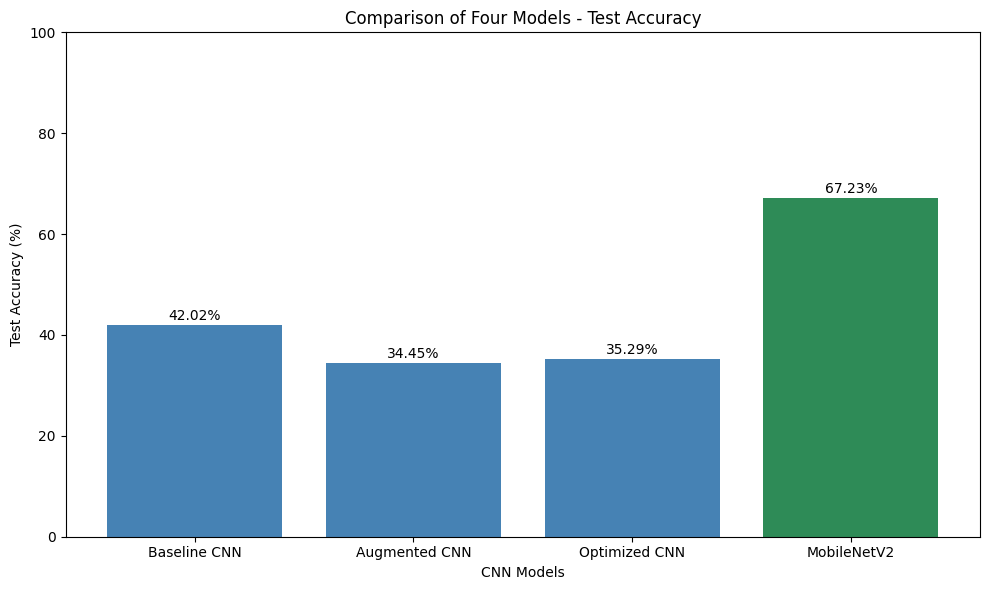

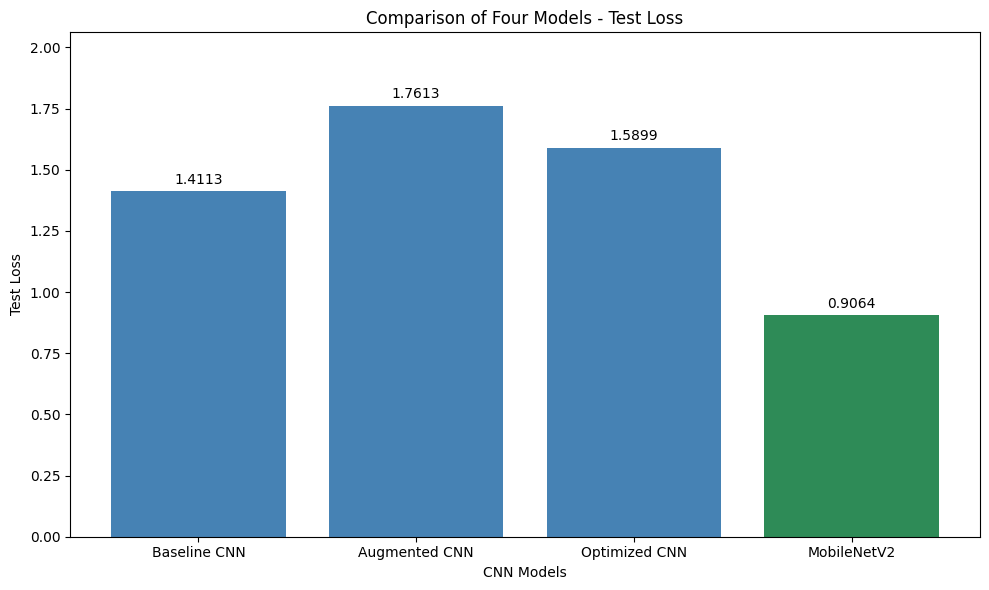

Final comparison graphs generated and saved successfully!


In [64]:

# Step 13.2 - Final Comparison Graphs

import matplotlib.pyplot as plt
import os

# Create results folder
os.makedirs("/content/solar_panel_results", exist_ok=True)

# Graph 1 - Test Accuracy Comparison
plt.figure(figsize=(10, 6))

bars = plt.bar(
    comparison_df["Model"],
    comparison_df["Test Accuracy (%)"],
    color=["steelblue", "steelblue", "steelblue", "seagreen"]
)

plt.title("Comparison of Four Models - Test Accuracy")
plt.xlabel("CNN Models")
plt.ylabel("Test Accuracy (%)")
plt.ylim(0, 100)

for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width()/2,
        height + 1,
        f"{height:.2f}%",
        ha="center"
    )

plt.tight_layout()
plt.savefig(
    "/content/solar_panel_results/final_test_accuracy.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# Graph 2 - Test Loss Comparison
plt.figure(figsize=(10, 6))

bars = plt.bar(
    comparison_df["Model"],
    comparison_df["Test Loss"],
    color=["steelblue", "steelblue", "steelblue", "seagreen"]
)

plt.title("Comparison of Four Models - Test Loss")
plt.xlabel("CNN Models")
plt.ylabel("Test Loss")

for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width()/2,
        height + 0.03,
        f"{height:.4f}",
        ha="center"
    )

plt.ylim(0, comparison_df["Test Loss"].max() + 0.3)
plt.tight_layout()
plt.savefig(
    "/content/solar_panel_results/final_test_loss.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

print("Final comparison graphs generated and saved successfully!")


In [65]:

# Step 13.3 - Save and Download Final Results

from google.colab import files
import os

results_dir = "/content/solar_panel_results"

# Save final comparison table
comparison_df.to_csv(
    os.path.join(results_dir, "final_model_comparison.csv"),
    index=False
)

print("Final comparison table saved!")

# Download final comparison table
files.download(
    os.path.join(results_dir, "final_model_comparison.csv")
)

# Download test accuracy graph
files.download(
    os.path.join(results_dir, "final_test_accuracy.png")
)

# Download test loss graph
files.download(
    os.path.join(results_dir, "final_test_loss.png")
)

print("All final comparison results downloaded successfully!")


Final comparison table saved!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

All final comparison results downloaded successfully!


In [68]:

from google.colab import files

files.download(
    "/content/solar_panel_results/final_test_loss.png"
)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Step 13.4 — Final Project Results and Conclusion

### Project Title
Deep Learning-Based Solar Panel Defect Classification Using Convolutional Neural Networks

### Experimental Results

Four deep learning models were developed and evaluated to classify solar panel images into six categories: Clean, Dusty, Bird-drop, Electrical-damage, Physical-Damage, and Snow-Covered.

| Model | Test Accuracy | Test Loss |
|---|---:|---:|
| Baseline CNN | 42.02% | 1.4113 |
| Augmented CNN | 34.45% | 1.7613 |
| Optimized CNN | 35.29% | 1.5899 |
| MobileNetV2 | **67.23%** | **0.9064** |

### Key Findings

1. The baseline CNN achieved 42.02% test accuracy.
2. Data augmentation did not improve test accuracy in the second experiment.
3. The optimized CNN, which incorporated dropout and training adjustments, achieved 35.29% test accuracy.
4. MobileNetV2, using transfer learning with pretrained weights, achieved the highest test accuracy of 67.23%.
5. MobileNetV2 correctly identified 13 of 14 Electrical-damage images, achieving 92.86% recall for this category.
6. Dusty and Physical-Damage images remained challenging, indicating opportunities for further improvement.

### Conclusion

This project investigated the effectiveness of convolutional neural networks and transfer learning for solar panel defect classification. Four models were trained and compared using the same six-class classification task.

The results demonstrated that MobileNetV2 outperformed the three custom CNN models, achieving 67.23% test accuracy and 0.9064 test loss. This represents an improvement of approximately 25.21 percentage points over the baseline CNN.

Although the transfer learning approach improved overall classification performance, challenges remained in identifying certain defect categories. Future work could explore additional training images, class balancing, fine-tuning pretrained layers, and improved image preprocessing.

Overall, the experiment demonstrates the potential of transfer learning for automated solar panel condition monitoring.